# Predicción de recompra en un e-commerce argentino
### Proyecto Final · Notebook integral de Ciencia de Datos
**Data Science I · Coderhouse** · Luciano Rivero · Noviembre 2026

---

**En una línea:** con los datos de cada compra, un modelo estima la probabilidad de que el cliente vuelva a comprar dentro de los 90 días, para que el negocio decida en quién invertir su presupuesto de retención.

**Índice**

1. Definición del problema y carga de datos
2. Limpieza y análisis exploratorio (EDA)
3. Preprocesamiento y feature engineering
4. Modelado y evaluación
5. Conclusiones y recomendaciones

**Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todas*. El dataset se descarga solo desde el repositorio público, no hay que subir archivos. Repositorio: [github.com/riveroluciano97-art/ecommerce-ar-data-science](https://github.com/riveroluciano97-art/ecommerce-ar-data-science).

---
# 1. Definición del problema y carga de datos

## 1.1 Contexto

Un e-commerce argentino de consumo masivo vende por cuatro canales: tienda propia, Mercado Libre, Instagram Shop y WhatsApp. En un proyecto anterior de Data Analytics sobre el mismo negocio se vio que los clientes recurrentes gastan cerca de un 25% más por ticket que los nuevos, y que el margen se achica en los eventos de descuento (Hot Sale, CyberMonday) y en los canales que cobran más comisión.

Retener clientes rinde más que captarlos, pero el presupuesto de retención (descuentos, remarketing, envío gratis) es limitado. Hoy se reparte sin criterio: se le regala margen a clientes que iban a volver igual y se gasta en otros que no van a volver de ninguna manera.

## 1.2 Objetivo y pregunta analítica

> **¿Qué clientes tienen alta probabilidad de volver a comprar dentro de los 90 días posteriores a una compra, y en cuáles conviene invertir para retenerlos?**

Objetivo medible: construir un modelo que, al momento de cada compra, estime la probabilidad de recompra a 90 días y supere en accuracy y en ROC-AUC a dos referencias simples: predecir siempre la clase mayoritaria y la regla intuitiva "si ya compró antes, vuelve".

## 1.3 Tipo de problema

Es un problema de **clasificación binaria supervisada**.

- **Variable objetivo (target):** `recompra_90d`. Vale 1 si el cliente vuelve a comprar dentro de los 90 días siguientes a la compra y 0 si no.
- **Unidad de observación:** una compra. Cada fila describe la compra y el estado del cliente *en ese momento*.
- **Métricas:** al ser clasificación, se evalúa con accuracy, precision, recall, F1-Score, matriz de confusión y curva ROC (AUC).

## 1.4 Fuente de los datos

`ventas_ds.csv` es un dataset **sintético**: lo generé con un script de Python (`scripts/generar_dataset_ds.py`, semilla 42) que simula el comportamiento de los clientes con reglas de negocio realistas del mercado argentino (inflación mensual, eventos de descuento, comisiones por canal). El script, el CSV y el diccionario de datos están publicados en el repositorio, así que el dataset es reproducible.

**Regla anti-leakage del dataset:** todas las variables de historia del cliente (`compras_previas`, `dias_desde_ultima_compra`, `gasto_previo_acum`, `antiguedad_dias`) se calculan solo con compras *anteriores* a la fecha de la fila. El target es lo único que mira hacia adelante.

## 1.5 Librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

SEMILLA = 42                      # misma semilla en todo lo que tenga azar: resultados reproducibles
pd.set_option('display.max_columns', None)

In [2]:
# Estilo visual único para todos los gráficos del notebook
AZUL = '#2a78d6'      # serie principal · cliente recurrente · "volvió"
NARANJA = '#eb6834'   # cliente nuevo
GRIS = '#a8a7a1'      # categoría de contraste ("no volvió")
ROJO = '#e34948'      # polo negativo (correlaciones y coeficientes negativos)
TEXTO = '#0b0b0b'
TEXTO_2 = '#52514e'
GRILLA = '#e6e5e1'

FUENTE = 'DejaVu Sans'      # fuente por defecto de matplotlib: se ve igual en Colab y en local

sns.set_theme(style='whitegrid', font=FUENTE, rc={
    'axes.edgecolor': GRILLA, 'grid.color': GRILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': TEXTO_2, 'axes.labelsize': 9.5,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'text.color': TEXTO, 'legend.frameon': False, 'legend.fontsize': 9,
    'text.parse_math': False,              # el signo $ se muestra como texto, no como fórmula
    'figure.dpi': 110,
})


def titular(ax, titulo, subtitulo):
    """Título que cuenta el hallazgo y subtítulo que dice qué se está graficando."""
    ax.set_title(titulo, loc='left', fontsize=12, fontweight='bold', color=TEXTO, pad=26)
    ax.annotate(subtitulo, xy=(0, 1), xycoords='axes fraction', xytext=(0, 9),
                textcoords='offset points', fontsize=9, color=TEXTO_2, va='bottom')


def pct(valor, decimales=1):
    """Porcentaje con coma decimal: 0.794 -> '79,4%'."""
    return f'{valor * 100:.{decimales}f}%'.replace('.', ',')


def miles(valor):
    """Entero con punto de miles: 7617 -> '7.617'."""
    return f'{int(valor):,}'.replace(',', '.')


def pesos(valor):
    """Pesos con punto de miles: 89024.7 -> '$89.025'."""
    return '$' + f'{valor:,.0f}'.replace(',', '.')

## 1.6 Ingesta

In [3]:
# El CSV se lee directo desde el repositorio público: el notebook corre en cualquier entorno
URL_DATASET = ('https://raw.githubusercontent.com/riveroluciano97-art/'
               'ecommerce-ar-data-science/main/data/ventas_ds.csv')

df_crudo = pd.read_csv(URL_DATASET)

filas, columnas = df_crudo.shape
print(f'Dimensiones: {miles(filas)} compras x {columnas} columnas | {miles(df_crudo["id_cliente"].nunique())} clientes')
display(df_crudo.head())

Dimensiones: 7.617 compras x 23 columnas | 4.208 clientes


,id_venta,fecha,id_cliente,provincia,fecha_alta_cliente,antiguedad_dias,compras_previas,dias_desde_ultima_compra,gasto_previo_acum,canal,comision_canal_pct,categoria,producto,precio_unitario,costo_unitario,cantidad,monto,descuento_pct,medio_pago,cuotas,es_evento,indice_inflacion,recompra_90d
0,1,2025-01-01,335,CABA,2025-01-01,0,0,NaN,0.00,Instagram Shop,0.08,Indumentaria,Vestido midi,56018.26,30959.05,1,56018.26,0.00,Tarjeta de débito,1,False,1.045,1.0
1,2,2025-01-01,455,Buenos Aires,2025-01-01,0,0,NaN,0.00,Instagram Shop,0.08,Hogar,Set sábanas,40803.13,24461.18,1,40803.13,0.00,Billetera virtual,1,False,1.045,0.0
2,3,2025-01-01,1185,Buenos Aires,2024-03-10,297,4,39.0,330802.50,Instagram Shop,0.08,Belleza,Esmalte gel,20291.41,9984.82,3,60874.23,0.00,Tarjeta de crédito,6,False,1.045,1.0
3,4,2025-01-01,1913,Mendoza,2024-09-07,116,2,17.0,156711.14,Tienda propia,0.06,Indumentaria,Buzo canguro,27431.98,14441.13,2,54863.95,0.00,Transferencia,1,False,1.045,1.0
4,5,2025-01-01,2286,Buenos Aires,2025-01-01,0,0,NaN,0.00,Mercado Libre,0.14,Indumentaria,Campera puffer,59662.55,32486.89,1,56679.43,0.05,Billetera virtual,1,False,1.045,0.0


**Diccionario de datos resumido**

| Grupo | Columnas | Qué describen |
|---|---|---|
| Identificadores y fechas | `id_venta`, `id_cliente`, `fecha`, `fecha_alta_cliente` | Quién compró y cuándo |
| Historia del cliente (hasta esa compra) | `antiguedad_dias`, `compras_previas`, `dias_desde_ultima_compra`, `gasto_previo_acum` | Qué tan conocido y activo es el cliente |
| La compra | `canal`, `comision_canal_pct`, `categoria`, `producto`, `precio_unitario`, `costo_unitario`, `cantidad`, `monto`, `descuento_pct`, `medio_pago`, `cuotas`, `es_evento` | Qué compró, por dónde y en qué condiciones |
| Contexto | `provincia`, `indice_inflacion` | Dónde vive el cliente y el índice de precios del mes |
| **Target** | `recompra_90d` | 1 si volvió a comprar dentro de los 90 días |

---
# 2. Limpieza y análisis exploratorio (EDA)

## 2.1 Diagnóstico: tipos de datos, nulos y duplicados

In [4]:
df_crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 7617 entries, 0 to 7616
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_venta                  7617 non-null   int64  
 1   fecha                     7617 non-null   str    
 2   id_cliente                7617 non-null   int64  
 3   provincia                 7617 non-null   str    
 4   fecha_alta_cliente        7617 non-null   str    
 5   antiguedad_dias           7617 non-null   int64  
 6   compras_previas           7617 non-null   int64  
 7   dias_desde_ultima_compra  3863 non-null   float64
 8   gasto_previo_acum         7617 non-null   float64
 9   canal                     7617 non-null   str    
 10  comision_canal_pct        7617 non-null   float64
 11  categoria                 7617 non-null   str    
 12  producto                  7617 non-null   str    
 13  precio_unitario           7617 non-null   float64
 14  costo_unitario     

In [5]:
# Nulos por columna (cantidad y porcentaje) y duplicados
diagnostico_nulos = pd.DataFrame({
    'nulos': df_crudo.isnull().sum(),
    '% nulos': (df_crudo.isnull().mean() * 100).round(2),
}).sort_values('nulos', ascending=False)
display(diagnostico_nulos[diagnostico_nulos['nulos'] > 0])

print(f'Filas duplicadas completas: {df_crudo.duplicated().sum()}')
print(f'Ventas con id_venta repetido: {df_crudo.duplicated(subset="id_venta").sum()}')

,nulos,% nulos
dias_desde_ultima_compra,3754,49.28
recompra_90d,1134,14.89
medio_pago,232,3.05


Filas duplicadas completas: 0
Ventas con id_venta repetido: 0


In [6]:
# Rangos de las variables numéricas: ¿hay valores imposibles?
display(df_crudo.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
id_venta,7617.0,3809.00,2198.98,1.00,1905.00,3809.00,5713.00,7617.00
id_cliente,7617.0,3134.37,1827.50,1.00,1549.00,3099.00,4743.00,6300.00
antiguedad_dias,7617.0,99.72,146.18,0.00,0.00,20.00,156.00,903.00
compras_previas,7617.0,1.93,3.29,0.00,0.00,1.00,2.00,28.00
dias_desde_ultima_compra,3863.0,67.14,51.56,3.00,32.00,52.00,86.00,504.00
gasto_previo_acum,7617.0,288504.26,534734.39,0.00,0.00,18570.51,339613.91,4994735.32
comision_canal_pct,7617.0,0.09,0.05,0.03,0.06,0.08,0.14,0.17
precio_unitario,7617.0,113403.86,86503.49,12179.90,47776.05,85030.33,150423.87,394586.64
costo_unitario,7617.0,72161.04,62657.90,6194.50,26086.29,48652.15,94931.15,284047.13
cantidad,7617.0,1.68,0.78,1.00,1.00,2.00,2.00,4.00


**Qué encontré y qué voy a hacer con cada problema**

| Problema | Evidencia | Decisión |
|---|---|---|
| Errores de tipo | `fecha` y `fecha_alta_cliente` llegan como texto, no como fechas. | Convertir a `datetime`. |
| Duplicados | No hay filas ni ventas repetidas. | Nada que eliminar; el control queda documentado. |
| Valores imposibles | El `describe()` no muestra precios negativos, cantidades en 0 ni descuentos fuera de rango. | Lo confirmo con un filtro de reglas de negocio. |
| Nulos en `recompra_90d` (14,9%) | Son compras de los últimos 90 días del período: no hay ventana completa para saber si el cliente volvió. | Excluirlas: falta justo la etiqueta que se quiere predecir. **Nunca rellenar con 0.** |
| Nulos en `dias_desde_ultima_compra` (49,3%) | Coinciden con las primeras compras: no existe una compra anterior. | No es un error. Se crea la bandera `es_primera_compra` y el valor se imputa dentro del pipeline (sección 3). |
| Nulos en `medio_pago` (3,0%) | Dato no informado. | Recuperar lo deducible por regla de negocio y marcar el resto como `"No informado"`. |
| Outliers en `monto` | Máximo de \$1,3 millones contra una mediana de \$122 mil. | Son compras reales de varias unidades: se conservan (se analiza en el gráfico 1). |

## 2.2 Saneamiento

In [7]:
df = df_crudo.copy()          # trabajo sobre una copia: el crudo queda intacto
bitacora = [('Dataset crudo', len(df))]

# --- Paso 1. Errores de tipo: fechas de texto a datetime ---
df['fecha'] = pd.to_datetime(df['fecha'])
df['fecha_alta_cliente'] = pd.to_datetime(df['fecha_alta_cliente'])

# --- Paso 2. Duplicados: se eliminan si aparecen (hoy no hay) ---
df = df.drop_duplicates(subset='id_venta', keep='first')
bitacora.append(('Sin duplicados', len(df)))

# --- Paso 3. Reglas de negocio: cada fila tiene que ser una venta posible ---
monto_esperado = df['cantidad'] * df['precio_unitario'] * (1 - df['descuento_pct'])
filas_validas = (
    (df['precio_unitario'] > 0) & (df['costo_unitario'] > 0) & (df['cantidad'] >= 1) &
    (df['descuento_pct'] >= 0) & (df['descuento_pct'] <= 0.25) &
    (df['fecha_alta_cliente'] <= df['fecha']) &                 # el alta no puede ser posterior a la compra
    (np.abs(df['monto'] - monto_esperado) <= 1)                 # monto = cantidad x precio x (1 - descuento)
)
print(f'Filas que violan alguna regla de negocio: {(~filas_validas).sum()}')
df = df[filas_validas]
bitacora.append(('Reglas de negocio', len(df)))

Filas que violan alguna regla de negocio: 0


In [8]:
# --- Paso 4. Target: solo compras con la ventana de 90 días completa ---
# Los datos terminan el 30/06/2026, así que una compra posterior al 01/04/2026 no tiene 90 días de observación
FECHA_CORTE = pd.Timestamp('2026-04-01')

posteriores = df[df['fecha'] > FECHA_CORTE]
print('Target en las compras posteriores al corte:')
print(posteriores['recompra_90d'].value_counts(dropna=False).to_string())

df = df[df['fecha'] <= FECHA_CORTE].copy()
df['recompra_90d'] = df['recompra_90d'].astype(int)             # ya sin nulos: 0/1 entero
bitacora.append(('Ventana de 90 días completa', len(df)))
print(f'\nNulos en el target después del filtro: {df["recompra_90d"].isnull().sum()}')

Target en las compras posteriores al corte:
recompra_90d
NaN    1134
1.0     207

Nulos en el target después del filtro: 0


Después del corte hay 1.134 compras sin target y 207 con target 1. Esas 207 tampoco se pueden conservar: en ese tramo solo quedaron etiquetadas las compras en las que el cliente *ya* volvió, y ninguna pudo ser etiquetada como 0. Dejarlas le enseñaría al modelo que al final del período todos recompran, lo cual es un artefacto de cómo se armó el dato y no un comportamiento real.

In [9]:
# --- Paso 5. Nulos de medio_pago ---
# Regla de negocio: solo se puede pagar en más de una cuota con tarjeta de crédito. Verifico que se cumple:
print('Medio de pago en las compras en cuotas:')
print(df[df['cuotas'] > 1]['medio_pago'].value_counts(dropna=False).to_string())

nulo_en_cuotas = df['medio_pago'].isnull() & (df['cuotas'] > 1)
df.loc[nulo_en_cuotas, 'medio_pago'] = 'Tarjeta de crédito'       # recuperados con certeza
restantes = df['medio_pago'].isnull().sum()
df['medio_pago'] = df['medio_pago'].fillna('No informado')        # constante: no usa estadísticas del dataset
print(f'\nRecuperados por regla: {nulo_en_cuotas.sum()} | Marcados "No informado": {restantes}')

Medio de pago en las compras en cuotas:
medio_pago
Tarjeta de crédito    1247
NaN                     39

Recuperados por regla: 39 | Marcados "No informado": 145


In [10]:
# --- Paso 6. Variables derivadas que se usan en el EDA y en el modelo (se explican en la sección 3) ---
df['es_primera_compra'] = df['compras_previas'] == 0
df['tipo_cliente'] = df['es_primera_compra'].map({True: 'Nuevo', False: 'Recurrente'})

INDICE_BASE = df_crudo['indice_inflacion'].min()                  # enero 2025, primer mes del dataset
df['monto_real'] = (df['monto'] / df['indice_inflacion'] * INDICE_BASE).round(2)

# Verificación: los nulos de recencia son exactamente las primeras compras
print('¿Recencia nula = primera compra, fila por fila?:',
      (df['dias_desde_ultima_compra'].isnull() == df['es_primera_compra']).all())

display(pd.DataFrame(bitacora, columns=['paso', 'filas']))
print(f'Dataset saneado: {miles(len(df))} compras de {miles(df["id_cliente"].nunique())} clientes | '
      f'{df["fecha"].min().date()} a {df["fecha"].max().date()}')
print('Nulos que quedan:', df.isnull().sum()[df.isnull().sum() > 0].to_dict())

¿Recencia nula = primera compra, fila por fila?: True


,paso,filas
0,Dataset crudo,7617
1,Sin duplicados,7617
2,Reglas de negocio,7617
3,Ventana de 90 días completa,6276


Dataset saneado: 6.276 compras de 3.496 clientes | 2025-01-01 a 2026-04-01
Nulos que quedan: {'dias_desde_ultima_compra': 3042}


**Resultado del saneamiento.** Quedan 6.276 compras de 3.496 clientes, con fechas bien tipadas, sin duplicados, sin filas que violen reglas de negocio y con el target completo. El único nulo que queda es el de `dias_desde_ultima_compra` en las primeras compras: no se imputa acá a propósito, porque imputar con una estadística (la mediana) antes de separar train y test sería *data leakage*. Se resuelve dentro del pipeline de la sección 3.

Las dos imputaciones hechas acá (regla de las cuotas y la constante `"No informado"`) no usan ninguna estadística calculada sobre el dataset, así que no filtran información entre train y test.

## 2.3 Balance del target

In [11]:
balance = df['recompra_90d'].value_counts().sort_index()
print(pd.DataFrame({'compras': balance, 'proporción': (balance / len(df)).map(pct)})
        .rename(index={0: 'No volvió (0)', 1: 'Volvió en 90 días (1)'}).to_string())

                       compras proporción
recompra_90d                             
No volvió (0)             3752      59,8%
Volvió en 90 días (1)     2524      40,2%


El 40,2% de las compras tuvo recompra en 90 días y el 59,8% no. Las clases están razonablemente balanceadas, así que no hace falta aplicar técnicas de balanceo y el accuracy es una métrica legible. Igual lo acompaño con precision, recall y F1, porque un modelo que dijera siempre "no vuelve" ya acertaría el 59,8% de las veces sin servir para nada.

## 2.4 Análisis exploratorio visual

Seis gráficos, cada uno elegido porque alimenta una decisión posterior de preprocesamiento o de modelado. Los montos están en pesos constantes de enero 2025 (`monto_real`) para que la inflación no distorsione las comparaciones.

### Gráfico 1 · ¿Cómo se distribuye el monto de las compras?

Mediana $89.025 | media $125.874 | asimetría 2.09 | límite de outliers $350.809 | 6,2% de las compras por encima


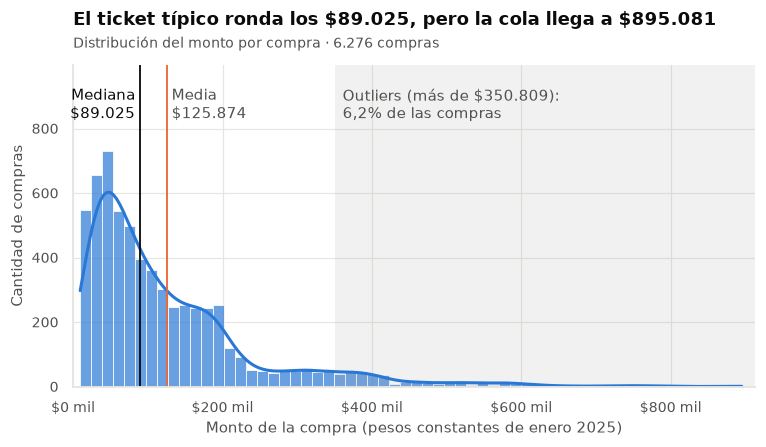

In [12]:
mediana = df['monto_real'].median()
media = df['monto_real'].mean()
q1, q3 = df['monto_real'].quantile([0.25, 0.75])
limite_outliers = q3 + 1.5 * (q3 - q1)                      # regla de 1,5 x IQR
peso_outliers = (df['monto_real'] > limite_outliers).mean()
print(f'Mediana {pesos(mediana)} | media {pesos(media)} | asimetría {df["monto_real"].skew():.2f} | '
      f'límite de outliers {pesos(limite_outliers)} | {pct(peso_outliers)} de las compras por encima')

monto_miles = df['monto_real'] / 1000
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(monto_miles, bins=60, kde=True, color=AZUL, alpha=0.7, edgecolor='white',
             linewidth=0.5, line_kws={'linewidth': 2}, ax=ax)

# Zona de outliers sombreada y líneas de referencia
ax.axvspan(limite_outliers / 1000, monto_miles.max() * 1.02, color=GRIS, alpha=0.15, linewidth=0)
ax.axvline(mediana / 1000, color=TEXTO, linewidth=1.2)
ax.axvline(media / 1000, color=NARANJA, linewidth=1.2)
ax.set_ylim(0, ax.get_ylim()[1] * 1.3)          # aire arriba para las etiquetas
techo = ax.get_ylim()[1]
ax.text(mediana / 1000 - 6, techo * 0.93, f'Mediana\n{pesos(mediana)}', ha='right', va='top', fontsize=9.5, color=TEXTO)
ax.text(media / 1000 + 6, techo * 0.93, f'Media\n{pesos(media)}', ha='left', va='top', fontsize=9.5, color=TEXTO_2)
ax.text(limite_outliers / 1000 + 10, techo * 0.93,
        f'Outliers (más de {pesos(limite_outliers)}):\n{pct(peso_outliers)} de las compras',
        ha='left', va='top', fontsize=9.5, color=TEXTO_2)

ax.set_xlim(0, monto_miles.max() * 1.02)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f} mil'.replace(',', '.')))
ax.set_xlabel('Monto de la compra (pesos constantes de enero 2025)')
ax.set_ylabel('Cantidad de compras')
titular(ax, f'El ticket típico ronda los {pesos(mediana)}, pero la cola llega a {pesos(df["monto_real"].max())}',
        f'Distribución del monto por compra · {len(df):,} compras'.replace(',', '.'))
plt.show()

**Qué se ve.** La distribución tiene un fuerte sesgo a la derecha (asimetría de 2,09): la media (\$125.874) supera en 41% a la mediana (\$89.025). El 6,2% de las compras queda por encima de \$350.809, el límite de outliers según la regla de 1,5 × IQR.

**Qué implica.** Esos outliers son compras reales de varias unidades o de Tecnología, no errores, así que se conservan. Para describir el ticket típico uso la mediana, no la media. Para el modelo, la variable entra en pesos constantes y escalada (sección 3.4), y conviene comparar un modelo lineal con uno de árboles, que no es sensible a los outliers.

### Gráfico 2 · ¿La historia del cliente predice si va a volver?

,compras_previas,mean,count,etiqueta,recompra_pct
0,0,0.240302,3042,0\n(primera compra),24.030243
1,1,0.362129,1146,1,36.212914
2,2,0.504521,553,2,50.452080
3,3,0.551451,379,3,55.145119
4,4,0.683794,253,4,68.379447
5,5,0.794020,903,5 o más,79.401993


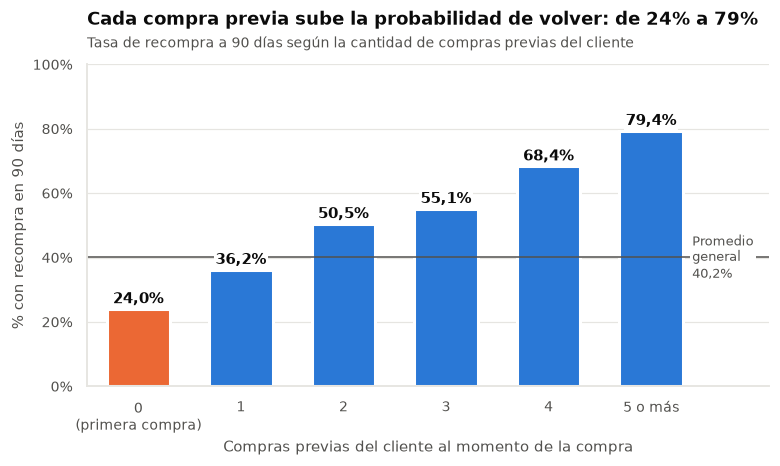

In [13]:
# Agrupo 5 o más compras previas en un solo tramo para que cada barra tenga volumen suficiente
tramo_previas = df['compras_previas'].clip(upper=5)
recompra_por_previas = (df.groupby(tramo_previas)['recompra_90d']
                          .agg(['mean', 'count']).reset_index())
recompra_por_previas['etiqueta'] = ['0\n(primera compra)', '1', '2', '3', '4', '5 o más']
recompra_por_previas['recompra_pct'] = recompra_por_previas['mean'] * 100
display(recompra_por_previas)

fig, ax = plt.subplots(figsize=(8, 3.8))
colores = [NARANJA] + [AZUL] * 5          # la primera compra (cliente nuevo) en naranja
sns.barplot(data=recompra_por_previas, x='etiqueta', y='recompra_pct', hue='etiqueta',
            palette=colores, legend=False, saturation=1, width=0.62, edgecolor='white', linewidth=2, ax=ax)
for barra, valor in zip(ax.patches, recompra_por_previas['mean']):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.8, pct(valor),
            ha='center', fontsize=10, fontweight='bold', color=TEXTO, zorder=5,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})

promedio = df['recompra_90d'].mean()
ax.axhline(promedio * 100, color=TEXTO_2, linewidth=1)
# Etiqueta del promedio a la derecha de la última barra, en un margen propio
ax.set_xlim(-0.5, 6.15)
ax.text(5.4, promedio * 100, f'Promedio\ngeneral\n{pct(promedio)}', ha='left', va='center',
        fontsize=8.5, color=TEXTO_2, linespacing=1.3,
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5})

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis='x', visible=False)
ax.set_xlabel('Compras previas del cliente al momento de la compra')
ax.set_ylabel('% con recompra en 90 días')
titular(ax, f'Cada compra previa sube la probabilidad de volver: de {pct(recompra_por_previas["mean"].iloc[0], 0)} '
            f'a {pct(recompra_por_previas["mean"].iloc[-1], 0)}',
        'Tasa de recompra a 90 días según la cantidad de compras previas del cliente')
plt.show()

**Qué se ve.** La relación es creciente y sostenida: un cliente en su primera compra vuelve en el 24,0% de los casos; con una compra previa, en el 36,2%; con dos, en el 50,5%; y con cinco o más, en el 79,4%. Las primeras compras son casi la mitad del dataset (3.042 de 6.276).

**Qué implica.** La recurrencia genera recurrencia, y el cuello de botella está en convertir la primera compra en la segunda. `compras_previas` apunta a ser una de las variables más importantes del modelo.

### Gráfico 3 · ¿Los clientes que vuelven compran más seguido?

,count,mean,std,min,25%,50%,75%,max
resultado,,,,,,,,
Volvió en 90 días,1793.0,51.8,41.4,3.0,25.0,40.0,65.0,424.0
No volvió,1441.0,84.8,56.7,7.0,45.0,71.0,108.0,504.0


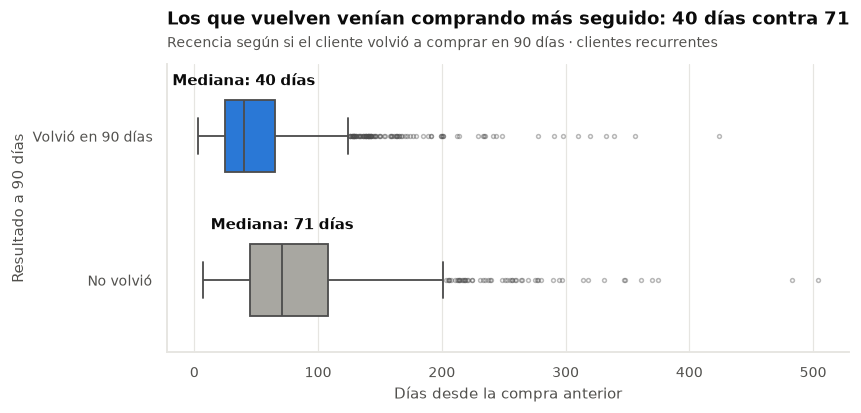

In [14]:
recurrentes = df[df['es_primera_compra'] == False].copy()      # la recencia solo existe para ellos
recurrentes['resultado'] = recurrentes['recompra_90d'].map({1: 'Volvió en 90 días', 0: 'No volvió'})
orden = ['Volvió en 90 días', 'No volvió']
display(recurrentes.groupby('resultado')['dias_desde_ultima_compra'].describe().loc[orden].round(1))

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.boxplot(data=recurrentes, x='dias_desde_ultima_compra', y='resultado', order=orden,
            hue='resultado', palette={'Volvió en 90 días': AZUL, 'No volvió': GRIS}, legend=False, saturation=1,
            width=0.5, linewidth=1.2, fliersize=2.5, flierprops={'alpha': 0.4}, ax=ax)

medianas = recurrentes.groupby('resultado')['dias_desde_ultima_compra'].median()
for posicion, resultado in enumerate(orden):
    ax.text(medianas[resultado], posicion - 0.33, f'Mediana: {medianas[resultado]:.0f} días',
            ha='center', va='bottom', fontsize=9.5, color=TEXTO, fontweight='bold')

ax.set_xlabel('Días desde la compra anterior')
ax.set_ylabel('Resultado a 90 días')
ax.grid(axis='y', visible=False)
titular(ax, f'Los que vuelven venían comprando más seguido: {medianas[orden[0]]:.0f} días contra {medianas[orden[1]]:.0f}',
        'Recencia según si el cliente volvió a comprar en 90 días · clientes recurrentes')
plt.show()

**Qué se ve.** Entre los clientes recurrentes, la mediana de recencia de quienes vuelven es de 40 días, contra 71 de quienes no vuelven. El 75% de los que vuelven venía de comprar hace menos de 65 días. Los dos grupos tienen outliers que superan los 400 días: clientes que reaparecen después de más de un año.

**Qué implica.** A medida que el cliente se "enfría", cae su probabilidad de volver. La recencia es una señal fuerte para el modelo.

### Gráfico 4 · ¿El canal de venta influye en la recompra?

tipo_cliente,Nuevo,Recurrente
canal,,
Tienda propia,0.333,0.675
WhatsApp,0.302,0.569
Instagram Shop,0.217,0.452
Mercado Libre,0.169,0.416


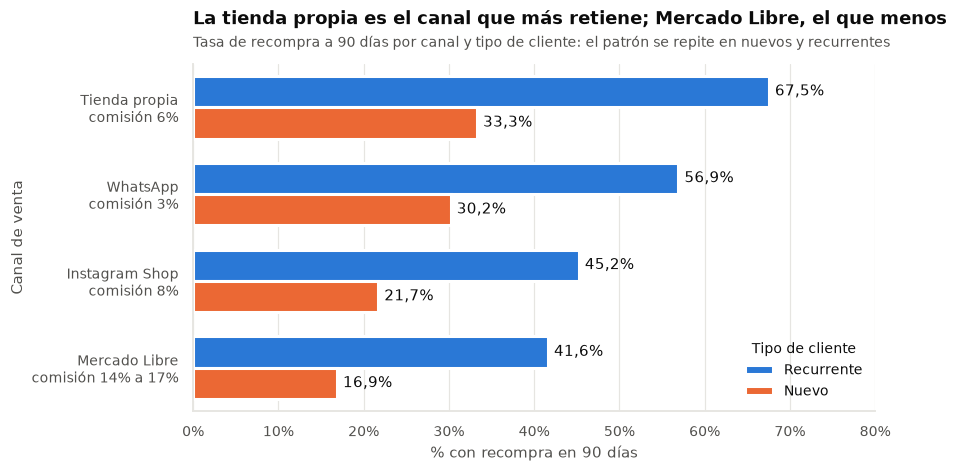

In [15]:
orden_canales = df.groupby('canal')['recompra_90d'].mean().sort_values(ascending=False).index.tolist()
display(df.pivot_table(index='canal', columns='tipo_cliente', values='recompra_90d', aggfunc='mean')
          .loc[orden_canales].round(3))

# Comisión de cada canal (Mercado Libre la subió de 14% a 17% en octubre 2025)
comision = df.groupby('canal')['comision_canal_pct'].agg(['min', 'max'])
def rango_comision(canal):
    minimo, maximo = comision.loc[canal, 'min'], comision.loc[canal, 'max']
    return f'{minimo:.0%}' if minimo == maximo else f'{minimo:.0%} a {maximo:.0%}'

fig, ax = plt.subplots(figsize=(8, 4.1))
sns.barplot(data=df.assign(recompra_pct=df['recompra_90d'] * 100), y='canal', x='recompra_pct',
            hue='tipo_cliente', order=orden_canales, hue_order=['Recurrente', 'Nuevo'],
            palette={'Recurrente': AZUL, 'Nuevo': NARANJA}, errorbar=None, saturation=1,
            width=0.72, edgecolor='white', linewidth=2, ax=ax)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[pct(barra.get_width() / 100) for barra in contenedor],
                 padding=4, fontsize=9.5, color=TEXTO)

ax.set_yticks(range(len(orden_canales)))
ax.set_yticklabels([f'{canal}\ncomisión {rango_comision(canal)}' for canal in orden_canales])
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis='y', visible=False)
ax.set_xlabel('% con recompra en 90 días')
ax.set_ylabel('Canal de venta')
ax.legend(title='Tipo de cliente', loc='lower right', title_fontsize=9)
titular(ax, 'La tienda propia es el canal que más retiene; Mercado Libre, el que menos',
        'Tasa de recompra a 90 días por canal y tipo de cliente: el patrón se repite en nuevos y recurrentes')
plt.show()

**Qué se ve.** El orden de los canales se repite en los dos tipos de cliente: en la tienda propia vuelve el 67,5% de los recurrentes y el 33,3% de los nuevos; en Mercado Libre, el 41,6% y el 16,9%. Como el patrón se sostiene dentro de cada grupo, no es solo un efecto de que un canal tenga más clientes nuevos que otro (Mercado Libre tiene más primeras compras, y por eso la comparación se hace dentro de cada grupo).

**Qué implica.** `canal` aporta información propia y entra al modelo. Como es una categoría sin orden, se codifica con One-Hot. Mercado Libre es además el canal con la comisión más alta (14% a 17%, contra 6% de la tienda propia): cada venta ahí deja menos margen y un cliente que vuelve menos.

### Gráfico 5 · ¿Los clientes que llegan en Hot Sale o CyberMonday vuelven?

mean            count           
tipo_cliente            Nuevo Recurrente Nuevo Recurrente
momento                                                  
Fuera de evento         0.290      0.574  2335       2787
Hot Sale / CyberMonday  0.076      0.432   707        447

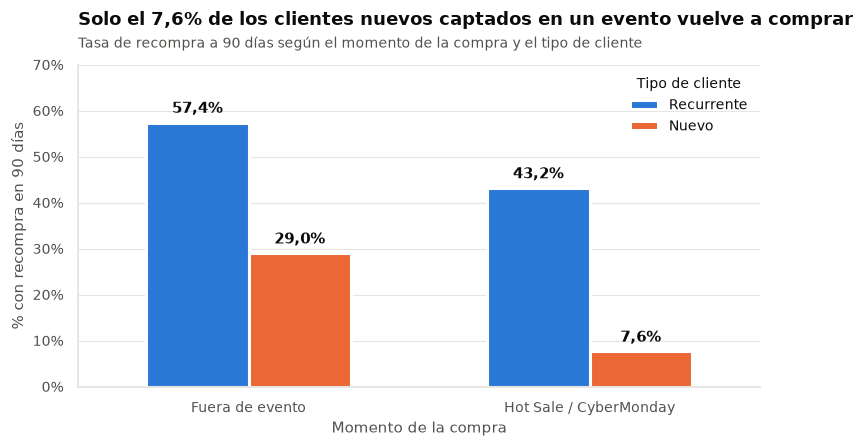

In [16]:
df['momento'] = df['es_evento'].map({False: 'Fuera de evento', True: 'Hot Sale / CyberMonday'})
display(df.pivot_table(index='momento', columns='tipo_cliente', values='recompra_90d',
                       aggfunc=['mean', 'count']).round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=df.assign(recompra_pct=df['recompra_90d'] * 100), x='momento', y='recompra_pct',
            hue='tipo_cliente', order=['Fuera de evento', 'Hot Sale / CyberMonday'],
            hue_order=['Recurrente', 'Nuevo'], palette={'Recurrente': AZUL, 'Nuevo': NARANJA},
            errorbar=None, saturation=1, width=0.6, edgecolor='white', linewidth=2, ax=ax)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[pct(barra.get_height() / 100) for barra in contenedor],
                 padding=4, fontsize=10, fontweight='bold', color=TEXTO)

nuevos_evento = df[(df['tipo_cliente'] == 'Nuevo') & (df['es_evento'] == True)]['recompra_90d'].mean()
ax.set_ylim(0, 70)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis='x', visible=False)
ax.set_xlabel('Momento de la compra')
ax.set_ylabel('% con recompra en 90 días')
ax.legend(title='Tipo de cliente', loc='upper right', title_fontsize=9)
titular(ax, f'Solo el {pct(nuevos_evento)} de los clientes nuevos captados en un evento vuelve a comprar',
        'Tasa de recompra a 90 días según el momento de la compra y el tipo de cliente')
plt.show()

**Qué se ve.** Los eventos bajan la recompra en los dos grupos, pero el golpe es mucho mayor en los clientes nuevos: pasan de 29,0% fuera de evento a 7,6% en Hot Sale o CyberMonday, casi cuatro veces menos. Los recurrentes bajan de 57,4% a 43,2%.

**Qué implica.** Los eventos atraen cazadores de ofertas: sirven para vender en el momento, no para sumar clientes que vuelvan. `es_evento` entra al modelo, y para el negocio es una señal de dónde *no* conviene gastar presupuesto de retención.

### Gráfico 6 · ¿Qué variables se relacionan con la recompra y cuáles se repiten entre sí?

,Recompra 90d (target),Compras previas,Gasto previo acumulado,Antigüedad del cliente,Días desde la última compra,Comisión del canal,Compra en evento,Descuento,Monto real
Recompra 90d (target),1.00,0.39,0.39,0.32,-0.37,-0.20,-0.18,-0.11,0.02
Compras previas,0.39,1.00,0.98,0.97,-0.36,-0.20,-0.11,-0.07,0.10
Gasto previo acumulado,0.39,0.98,1.00,0.94,-0.34,-0.19,-0.11,-0.07,0.10
Antigüedad del cliente,0.32,0.97,0.94,1.00,0.17,-0.16,-0.11,-0.07,0.10
Días desde la última compra,-0.37,-0.36,-0.34,0.17,1.00,0.18,0.00,-0.02,-0.00
Comisión del canal,-0.20,-0.20,-0.19,-0.16,0.18,1.00,0.02,0.03,-0.01
Compra en evento,-0.18,-0.11,-0.11,-0.11,0.00,0.02,1.00,0.60,0.09
Descuento,-0.11,-0.07,-0.07,-0.07,-0.02,0.03,0.60,1.00,-0.00
Monto real,0.02,0.10,0.10,0.10,-0.00,-0.01,0.09,-0.00,1.00


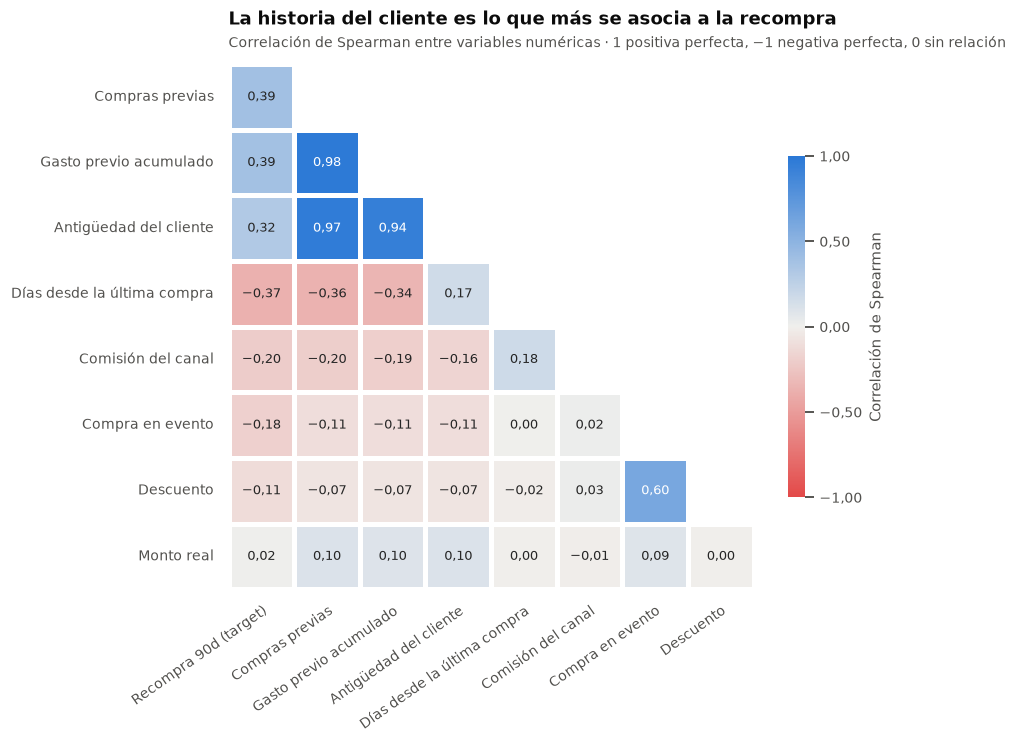

In [17]:
variables = {
    'recompra_90d': 'Recompra 90d (target)',
    'compras_previas': 'Compras previas',
    'gasto_previo_acum': 'Gasto previo acumulado',
    'antiguedad_dias': 'Antigüedad del cliente',
    'dias_desde_ultima_compra': 'Días desde la última compra',
    'comision_canal_pct': 'Comisión del canal',
    'es_evento': 'Compra en evento',
    'descuento_pct': 'Descuento',
    'monto_real': 'Monto real',
}

# Spearman se basa en rangos: no lo distorsionan los outliers de monto y gasto vistos en el gráfico 1.
# La recencia no existe en primeras compras: sus correlaciones se calculan solo con recurrentes.
correlacion = (df[list(variables)].astype(float).corr(method='spearman')
                 .rename(index=variables, columns=variables))
display(correlacion.round(2))

# Muestro solo el triángulo inferior sin la diagonal (cada par aparece una vez)
triangulo = correlacion.iloc[1:, :-1]
mascara = np.triu(np.ones_like(triangulo, dtype=bool), k=1)

def formatear(valor):
    texto = f'{valor:.2f}'
    return '0,00' if texto == '-0.00' else texto.replace('.', ',').replace('-', '−')

anotaciones = triangulo.map(formatear)
paleta_divergente = LinearSegmentedColormap.from_list('rojo_gris_azul', [ROJO, '#f0efec', AZUL])

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(triangulo, mask=mascara, cmap=paleta_divergente, vmin=-1, vmax=1, center=0,
            annot=anotaciones, fmt='', annot_kws={'fontsize': 8.5}, linewidths=2, linecolor='white',
            square=True, cbar_kws={'shrink': 0.65, 'label': 'Correlación de Spearman',
                                   'ticks': [-1, -0.5, 0, 0.5, 1]}, ax=ax)
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatear(v)))
ax.grid(False)
ax.tick_params(axis='x', rotation=35)
plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
titular(ax, 'La historia del cliente es lo que más se asocia a la recompra',
        'Correlación de Spearman entre variables numéricas · 1 positiva perfecta, −1 negativa perfecta, 0 sin relación')
plt.show()

**Qué se ve.** Las variables más asociadas a la recompra son las de historia del cliente: compras previas (0,39), gasto previo (0,39), recencia (−0,37) y antigüedad (0,32). Después vienen la comisión del canal (−0,20) y la compra en evento (−0,18); el monto casi no se relaciona (0,02). Usé Spearman, basado en rangos, porque el gráfico 1 mostró outliers que distorsionarían una correlación de Pearson. Las correlaciones de la recencia se calculan solo con clientes recurrentes, que son los únicos que la tienen.

**Qué implica.** Compras previas y gasto previo están muy correlacionadas entre sí (0,98, en parte porque las dos valen 0 en las primeras compras): son información redundante, y en la sección 3 me quedo con una sola. Ninguna variable tiene por sí sola una correlación con el target cercana a 1, lo que es una primera señal de que no hay una variable "filtrando" la respuesta. Correlación no implica causalidad: este mapa sirve para elegir variables, no para explicar el porqué.

## 2.5 Síntesis del EDA

| Hallazgo | Decisión que alimenta |
|---|---|
| `monto` y recencia tienen sesgo fuerte y outliers reales | Conservar los outliers, deflactar el monto y escalar las numéricas |
| La recompra crece con cada compra previa (24% → 79%) | `compras_previas` y `es_primera_compra` como variables centrales |
| Los que vuelven venían comprando más seguido (40 vs. 71 días) | `dias_desde_ultima_compra` entra al modelo |
| El canal y el evento cambian la recompra dentro de cada tipo de cliente | `canal` (One-Hot) y `es_evento` entran al modelo |
| `gasto_previo_acum` repite la información de `compras_previas` (0,98) | Descartar `gasto_previo_acum` |

---
# 3. Preprocesamiento y feature engineering

El orden de esta sección es deliberado para evitar *data leakage*:

1. Feature engineering **fila por fila** (no usa estadísticas del conjunto).
2. Selección de variables.
3. **Separación en train y test.**
4. Imputación, escalado y codificación **ajustados solo con train**, dentro de un `Pipeline`.

## 3.1 Feature engineering

Creé dos variables con criterio de negocio. Las dos se calculan con datos de la propia fila, así que hacerlo antes del split no filtra información del test.

| Variable nueva | Cómo se calcula | Por qué |
|---|---|---|
| `es_primera_compra` | `compras_previas == 0` | El gráfico 2 muestra que el salto más grande de recompra está entre la primera compra y las siguientes. Además le explica al modelo por qué falta la recencia en esas filas. |
| `monto_real` | `monto / indice_inflacion × índice de enero 2025` | Con la inflación del período, \$100.000 de enero 2025 no equivalen a \$100.000 de marzo 2026. En pesos constantes los montos son comparables y el modelo no confunde inflación con comportamiento. |

In [18]:
# Las dos variables se calcularon en el paso 6 de la limpieza porque el EDA las necesitaba.
# Son transformaciones fila por fila: el valor de una compra no depende de ninguna otra compra.
display(df[['fecha', 'compras_previas', 'es_primera_compra', 'monto', 'indice_inflacion', 'monto_real']]
          .sort_values('fecha').iloc[[0, len(df) // 2, -1]])

,fecha,compras_previas,es_primera_compra,monto,indice_inflacion,monto_real
0,2025-01-01,0,True,56018.26,1.0450,56018.26
3126,2025-08-23,2,False,254582.99,1.3713,194005.12
6275,2026-04-01,0,True,70314.53,1.7295,42485.51


En la tabla se ve el efecto de deflactar: cuanto más avanzado el período, mayor es el índice y más se achica el monto al pasarlo a pesos de enero 2025.

## 3.2 Selección de variables

In [19]:
TARGET = 'recompra_90d'

numericas = ['compras_previas', 'dias_desde_ultima_compra', 'antiguedad_dias',
             'monto_real', 'cantidad', 'descuento_pct', 'cuotas']
binarias = ['es_primera_compra', 'es_evento']
categoricas = ['canal', 'categoria', 'medio_pago', 'provincia']

variables_modelo = numericas + binarias + categoricas
descartadas = [col for col in df.columns if col not in variables_modelo + [TARGET]]

print(f'Variables que entran al modelo ({len(variables_modelo)}): {variables_modelo}')
print(f'\nVariables descartadas ({len(descartadas)}): {descartadas}')

Variables que entran al modelo (13): ['compras_previas', 'dias_desde_ultima_compra', 'antiguedad_dias', 'monto_real', 'cantidad', 'descuento_pct', 'cuotas', 'es_primera_compra', 'es_evento', 'canal', 'categoria', 'medio_pago', 'provincia']

Variables descartadas (13): ['id_venta', 'fecha', 'id_cliente', 'fecha_alta_cliente', 'gasto_previo_acum', 'comision_canal_pct', 'producto', 'precio_unitario', 'costo_unitario', 'monto', 'indice_inflacion', 'tipo_cliente', 'momento']


**Por qué uso estas 13 variables.** Todas se conocen en el momento de la compra, que es cuando el negocio necesitaría la predicción: la historia del cliente hasta ese día (`compras_previas`, `dias_desde_ultima_compra`, `antiguedad_dias`, `es_primera_compra`) y las condiciones de la compra (`canal`, `categoria`, `medio_pago`, `provincia`, `monto_real`, `cantidad`, `descuento_pct`, `cuotas`, `es_evento`).

**Por qué descarto las demás**

| Variable | Motivo del descarte |
|---|---|
| `id_venta`, `id_cliente` | Identificadores: no describen comportamiento, y el modelo podría memorizarlos. |
| `fecha`, `fecha_alta_cliente` | Una fecha cruda no generaliza a compras futuras. Su información útil ya está en `antiguedad_dias` y `es_evento`. La `fecha` se guarda aparte para la validación temporal de la sección 4.7. |
| `gasto_previo_acum` | Redundante con `compras_previas` (correlación de 0,98) y expresada en pesos corrientes de distintos meses, que no se pueden deflactar con un único índice. |
| `monto`, `precio_unitario`, `costo_unitario` | En pesos corrientes, distorsionados por la inflación. Los reemplaza `monto_real`. |
| `indice_inflacion` | Es un reloj disfrazado: crece mes a mes. Solo se usa para deflactar. |
| `comision_canal_pct` | Queda determinada por el canal y la fecha; `canal` ya aporta esa información. |
| `producto` | 60 valores distintos con pocas compras cada uno; `categoria` lo resume sin sumar 60 columnas. |
| `tipo_cliente`, `momento` | Etiquetas de texto de `es_primera_compra` y `es_evento`, creadas solo para los gráficos. |

**Dos aclaraciones sobre lo que sí entra**

- `antiguedad_dias` también está muy correlacionada con `compras_previas` (0,97), pero la conservo porque mide otra cosa: tiempo, no cantidad. Juntas le permiten al modelo distinguir a quien hizo cinco compras en dos meses de quien las hizo en un año, es decir, la frecuencia de compra.
- `provincia`, `medio_pago`, `cantidad` y `cuotas` no tienen una hipótesis de negocio fuerte detrás. Entran porque están disponibles al momento de la compra, y dejo que el modelo defina cuánto pesan. El punto 4.5 muestra que pesan menos que la historia del cliente, el evento y el canal.

**Chequeo de leakage.** Ninguna de las 13 variables usa información posterior a la compra: no hay conteos totales del cliente, ni fechas de compras siguientes, ni nada derivado del target.

## 3.3 Separación en train y test

La separación va **antes** de imputar, escalar o codificar. Uso 80% para entrenar y 20% para evaluar, con `stratify` para que los conjuntos mantengan la misma proporción de recompra y `random_state` fijo para que el resultado sea reproducible. Dentro de train reservo además un 25% como **validación**: sirve para comparar modelos y elegir uno sin tocar el test, que queda guardado para la medición final.

In [20]:
X = df[variables_modelo].copy()
X[binarias] = X[binarias].astype(int)          # True/False a 1/0
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)

# Dentro de train separo un subconjunto de validación, para elegir el modelo sin mirar el test
X_ajuste, X_validacion, y_ajuste, y_validacion = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA
)

print(f'Train:        {miles(len(X_train))} compras | recompra: {pct(y_train.mean())}')
print(f'  Ajuste:     {miles(len(X_ajuste))} compras | recompra: {pct(y_ajuste.mean())}')
print(f'  Validación: {miles(len(X_validacion))} compras | recompra: {pct(y_validacion.mean())}')
print(f'Test:         {miles(len(X_test))} compras | recompra: {pct(y_test.mean())}')

Train:        5.020 compras | recompra: 40,2%
  Ajuste:     3.765 compras | recompra: 40,2%
  Validación: 1.255 compras | recompra: 40,2%
Test:         1.256 compras | recompra: 40,2%


## 3.4 Transformaciones dentro de un pipeline

Cada tipo de variable recibe su tratamiento, y todo queda encapsulado en un `ColumnTransformer`:

| Variables | Transformación | Justificación |
|---|---|---|
| Numéricas | `SimpleImputer(strategy='median')` + `StandardScaler` | La única numérica con nulos es la recencia de las primeras compras: se imputa con la mediana de train y la bandera `es_primera_compra` le indica al modelo que ese valor es de relleno. El escalado lleva todas las numéricas a media 0 y desvío 1, para que la regresión logística no le dé más peso a una variable solo por estar en pesos y no en unidades. |
| Binarias | Sin transformar | Ya valen 0 o 1. |
| Categóricas | `OneHotEncoder` | Canal, categoría, medio de pago y provincia son **nominales**: no tienen un orden natural, así que una codificación ordinal (1, 2, 3...) le inventaría al modelo una jerarquía que no existe. One-Hot crea una columna 0/1 por valor. `handle_unknown='ignore'` evita errores si en el futuro aparece una categoría nueva. |

**Por qué no `RobustScaler`.** Por los outliers de los gráficos 1 y 3, el escalado robusto (mediana e IQR) parecía la opción natural. Lo descarté por un motivo concreto: después de imputar, la mitad de la columna de recencia vale exactamente la mediana, y variables como `cantidad` y `cuotas` tienen muy pocos valores distintos. En esos casos el IQR se achica o queda en un solo salto, y el escalado robusto deja de ser una medida razonable de dispersión. La celda siguiente lo muestra con los datos de train. Como control, también entreno un Random Forest, que no depende de la escala: si los outliers estuvieran perjudicando al modelo lineal, el Random Forest rendiría claramente mejor.

Al estar dentro del pipeline, la mediana, la media, el desvío y las categorías se aprenden **solo con train** (`fit`) y después se aplican a test (`transform`). El test nunca participa del ajuste.

In [21]:
def crear_preprocesador():
    """Devuelve un preprocesador nuevo (sin ajustar) para armar cada pipeline."""
    return ColumnTransformer(transformers=[
        ('numericas', Pipeline([('imputar', SimpleImputer(strategy='median')),
                                ('escalar', StandardScaler())]), numericas),
        ('binarias', 'passthrough', binarias),
        ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
    ])


# Demostración: se ajusta SOLO con train y se aplica a test
preprocesador_demo = crear_preprocesador().fit(X_train)
mediana_recencia = preprocesador_demo.named_transformers_['numericas']['imputar'].statistics_[numericas.index('dias_desde_ultima_compra')]

print(f'Mediana de recencia aprendida en train (valor de imputación): {mediana_recencia:.0f} días')

# Evidencia de por qué no uso RobustScaler: el IQR de la recencia se degenera después de imputar
recencia_imputada = X_train['dias_desde_ultima_compra'].fillna(mediana_recencia)
iqr_original = X_train['dias_desde_ultima_compra'].quantile(0.75) - X_train['dias_desde_ultima_compra'].quantile(0.25)
iqr_imputada = recencia_imputada.quantile(0.75) - recencia_imputada.quantile(0.25)
print(f'IQR de la recencia en train: {iqr_original:.0f} días sin imputar -> {iqr_imputada:.0f} días después de imputar '
      f'(desvío estándar: {recencia_imputada.std():.0f} días)')

print(f'Columnas después de transformar: {preprocesador_demo.transform(X_train).shape[1]} '
      f'({len(numericas)} numéricas + {len(binarias)} binarias + '
      f'{len(preprocesador_demo.named_transformers_["categoricas"].get_feature_names_out())} de One-Hot)')
print(f'Nulos en test después de transformar: {int(np.isnan(preprocesador_demo.transform(X_test)).sum())}')

Mediana de recencia aprendida en train (valor de imputación): 52 días
IQR de la recencia en train: 55 días sin imputar -> 4 días después de imputar (desvío estándar: 38 días)
Columnas después de transformar: 33 (7 numéricas + 2 binarias + 24 de One-Hot)
Nulos en test después de transformar: 0


---
# 4. Modelado y evaluación

**Cómo uso cada conjunto de datos**

| Conjunto | Tamaño | Para qué se usa |
|---|---|---|
| Ajuste (75% de train) | 3.765 compras | Entrenar los modelos candidatos |
| Validación (25% de train) | 1.255 compras | Detectar sobreajuste y **elegir** el modelo |
| Test | 1.256 compras | Medir el rendimiento final, **una sola vez**, con el modelo ya elegido |

Así ninguna decisión (qué modelo, qué parámetros) se toma mirando el test, y la métrica final es una estimación honesta de cómo rendiría el modelo con compras nuevas.

## 4.1 Puntos de referencia

Un modelo solo es bueno en comparación con algo. Antes de entrenar defino dos referencias:

- **Clase mayoritaria:** predecir siempre "no vuelve". Es el piso de cualquier clasificador.
- **Regla de negocio:** "si ya compró antes, vuelve". Es lo que haría hoy una persona del equipo comercial sin ningún modelo.

El modelo tiene que superarlas en **accuracy** (aciertos totales) y en **ROC-AUC** (capacidad de ordenar las compras de menor a mayor probabilidad de recompra), que es lo que el negocio necesita para repartir un presupuesto limitado.

In [22]:
def medir(y_real, prediccion, probabilidad):
    """Devuelve las métricas de clasificación de una predicción."""
    return {
        'accuracy': accuracy_score(y_real, prediccion),
        'precision': precision_score(y_real, prediccion, zero_division=0),
        'recall': recall_score(y_real, prediccion),
        'f1': f1_score(y_real, prediccion),
        'roc_auc': roc_auc_score(y_real, probabilidad),
    }


def evaluar(pipeline, X_eval, y_eval):
    """Métricas de un pipeline ya entrenado sobre un conjunto de datos."""
    return medir(y_eval, pipeline.predict(X_eval), pipeline.predict_proba(X_eval)[:, 1])


def medir_referencias(X_eval, y_eval):
    """Métricas de las dos referencias sobre un conjunto de datos."""
    siempre_no = np.zeros(len(y_eval), dtype=int)                 # clase mayoritaria: nadie vuelve
    regla = (X_eval['compras_previas'] > 0).astype(int)           # regla: si ya compró antes, vuelve
    return {'Ref. 1 · Clase mayoritaria': medir(y_eval, siempre_no, siempre_no),
            'Ref. 2 · Regla "ya compró antes"': medir(y_eval, regla, regla)}


# DummyClassifier confirma cuál es la clase mayoritaria en los datos de ajuste
mayoritaria = DummyClassifier(strategy='most_frequent').fit(X_ajuste, y_ajuste)
print(f'Clase mayoritaria según DummyClassifier: {mayoritaria.predict(X_validacion)[0]} (no vuelve)')

display(pd.DataFrame(medir_referencias(X_validacion, y_validacion)).T.round(3))

Clase mayoritaria según DummyClassifier: 0 (no vuelve)


,accuracy,precision,recall,f1,roc_auc
Ref. 1 · Clase mayoritaria,0.598,0.000,0.000,0.000,0.500
"Ref. 2 · Regla ""ya compró antes""",0.662,0.562,0.723,0.633,0.672


En validación, la clase mayoritaria acierta cerca del 60% pero no detecta ninguna recompra (recall y F1 en 0): confirma que el accuracy solo no alcanza. La regla de negocio es una referencia más exigente: acierta alrededor de dos de cada tres veces y detecta la mayoría de las recompras, pero se equivoca seguido cuando dice "vuelve" (precision baja) y solo sabe responder sí o no.

## 4.2 Entrenamiento y selección del modelo

Entreno dos tipos de modelo, cada uno dentro de un `Pipeline` que incluye el preprocesamiento:

- **Regresión logística:** modelo lineal, simple e interpretable. Cada variable empuja la probabilidad de recompra hacia arriba o hacia abajo.
- **Random Forest:** conjunto de árboles de decisión que captura relaciones no lineales e interacciones entre variables (por ejemplo, que el evento pese distinto en clientes nuevos y recurrentes, como mostró el gráfico 5). Lo pruebo con los parámetros por defecto y en una versión regularizada, con árboles menos profundos (`max_depth=8`) y al menos 10 compras por hoja (`min_samples_leaf=10`).

In [23]:
candidatos = {
    'Regresión logística': LogisticRegression(max_iter=1000, random_state=SEMILLA),
    'Random Forest (sin límites)': RandomForestClassifier(random_state=SEMILLA),
    'Random Forest (regularizado)': RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=10, random_state=SEMILLA),
}


def crear_pipeline(modelo):
    """Preprocesamiento + modelo en un solo objeto: todo se ajusta con los mismos datos."""
    return Pipeline([('preprocesamiento', crear_preprocesador()), ('modelo', modelo)])


filas_seleccion = {}
for nombre, modelo in candidatos.items():
    pipeline = crear_pipeline(modelo).fit(X_ajuste, y_ajuste)           # se entrena solo con ajuste
    en_ajuste = evaluar(pipeline, X_ajuste, y_ajuste)
    en_validacion = evaluar(pipeline, X_validacion, y_validacion)
    filas_seleccion[nombre] = {
        'accuracy en ajuste': en_ajuste['accuracy'],
        'accuracy en validación': en_validacion['accuracy'],
        'brecha de accuracy': en_ajuste['accuracy'] - en_validacion['accuracy'],
        'f1 en validación': en_validacion['f1'],
        'roc_auc en validación': en_validacion['roc_auc'],
    }

seleccion = pd.DataFrame(filas_seleccion).T
display(seleccion.round(3))

,accuracy en ajuste,accuracy en validación,brecha de accuracy,f1 en validación,roc_auc en validación
Regresión logística,0.731,0.740,-0.009,0.628,0.782
Random Forest (sin límites),1.000,0.722,0.278,0.614,0.742
Random Forest (regularizado),0.752,0.743,0.008,0.629,0.776


**Qué muestra la validación**

- **El Random Forest sin límites está sobreajustado.** Acierta el 100% de las compras con las que se entrenó y bastante menos en validación: memorizó los datos de ajuste en lugar de aprender el patrón general. Queda descartado.
- **Regularizarlo corrige el problema.** Con árboles menos profundos y hojas más grandes, la brecha entre ajuste y validación casi desaparece y el rendimiento en validación mejora.
- **La regresión logística y el Random Forest regularizado empatan.** Las diferencias de accuracy y F1 en validación están en el tercer decimal, y la regresión logística tiene el ROC-AUC algo más alto (0,782). La brecha negativa de la regresión logística (rinde apenas mejor en validación que en ajuste) no significa nada especial: es una variación normal del azar de la partición, y lo que importa es que sea chica.

**Modelo elegido: regresión logística.** Con un rendimiento equivalente, elijo el modelo más simple: es más fácil de explicarle al negocio, sus coeficientes se pueden leer uno por uno (punto 4.5) y ordena las compras igual o mejor, que es el uso que se le va a dar. El empate también dice algo sobre los datos: un modelo capaz de capturar relaciones no lineales no encuentra nada que el modelo lineal no haya aprovechado ya.

Llevo los dos a la evaluación final: la regresión logística como modelo elegido y el Random Forest regularizado como contraste.

## 4.3 Evaluación final en test

Con el modelo ya elegido, reentreno con **todo** el conjunto de train (ajuste + validación) para aprovechar todos los datos, y recién ahora mido en test.

In [24]:
finalistas = ['Regresión logística', 'Random Forest (regularizado)']

pipelines = {}
filas_test = medir_referencias(X_test, y_test)
brecha_train_test = {}
for nombre in finalistas:
    pipelines[nombre] = crear_pipeline(candidatos[nombre]).fit(X_train, y_train)    # todo train
    filas_test[nombre] = evaluar(pipelines[nombre], X_test, y_test)
    brecha_train_test[nombre] = (evaluar(pipelines[nombre], X_train, y_train)['accuracy']
                                 - filas_test[nombre]['accuracy'])

tabla_test = pd.DataFrame(filas_test).T
display(tabla_test.round(3))
print('Brecha de accuracy entre train y test:',
      {nombre: round(float(valor), 3) for nombre, valor in brecha_train_test.items()})

,accuracy,precision,recall,f1,roc_auc
Ref. 1 · Clase mayoritaria,0.598,0.000,0.000,0.000,0.500
"Ref. 2 · Regla ""ya compró antes""",0.666,0.571,0.687,0.624,0.670
Regresión logística,0.743,0.754,0.535,0.626,0.785
Random Forest (regularizado),0.737,0.746,0.525,0.616,0.783


Brecha de accuracy entre train y test: {'Regresión logística': -0.01, 'Random Forest (regularizado)': 0.015}


In [25]:
# Reporte por clase del modelo elegido
print(classification_report(y_test, pipelines['Regresión logística'].predict(X_test),
                            target_names=['No volvió', 'Volvió en 90 días'], digits=3))

                   precision    recall  f1-score   support

        No volvió      0.738     0.883     0.804       751
Volvió en 90 días      0.754     0.535     0.626       505

         accuracy                          0.743      1256
        macro avg      0.746     0.709     0.715      1256
     weighted avg      0.745     0.743     0.732      1256



### Gráfico 7 · Matrices de confusión

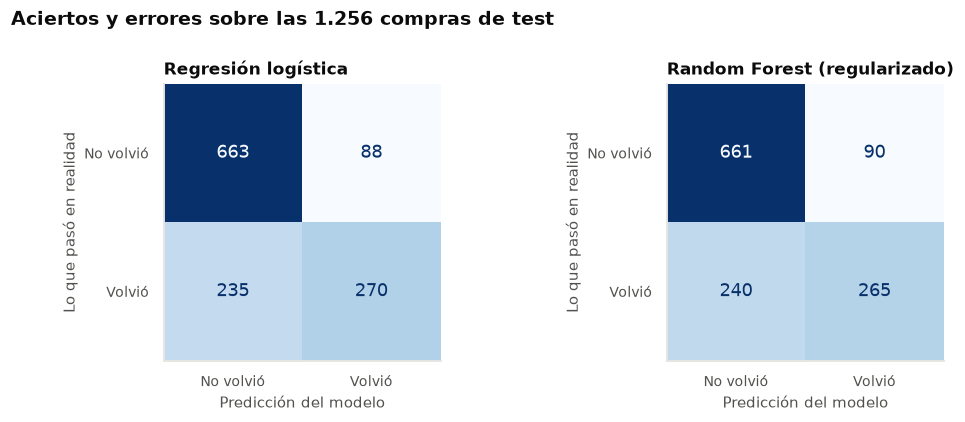

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 3.9))
etiquetas = ['No volvió', 'Volvió']

for eje, nombre in zip(ejes, finalistas):
    matriz = confusion_matrix(y_test, pipelines[nombre].predict(X_test))
    ConfusionMatrixDisplay(matriz, display_labels=etiquetas).plot(
        ax=eje, cmap='Blues', colorbar=False, values_format=',d')
    eje.set_title(nombre, fontsize=11, fontweight='bold', loc='left')
    eje.set_xlabel('Predicción del modelo')
    eje.set_ylabel('Lo que pasó en realidad')
    eje.grid(False)

fig.suptitle(f'Aciertos y errores sobre las {miles(len(y_test))} compras de test'.replace(',', '.'),
             x=0.02, ha='left', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

**Cómo leer la matriz de la regresión logística** (1.256 compras de test):

- **663 verdaderos negativos:** dijo "no vuelve" y no volvió.
- **270 verdaderos positivos:** dijo "vuelve" y volvió.
- **88 falsos positivos:** dijo "vuelve" y no volvió. Son clientes que el negocio daría por seguros y que en realidad se pierden.
- **235 falsos negativos:** dijo "no vuelve" y volvió. Son recompras que el modelo no anticipa: el costo es haber subestimado a esos clientes.

El modelo es conservador: cuando dice "vuelve", acierta 3 de cada 4 veces (precision de 75,4%), pero con el umbral estándar de 0,5 detecta solo el 53,5% de las recompras (recall). El Random Forest muestra el mismo perfil.

### Gráfico 8 · Curvas ROC

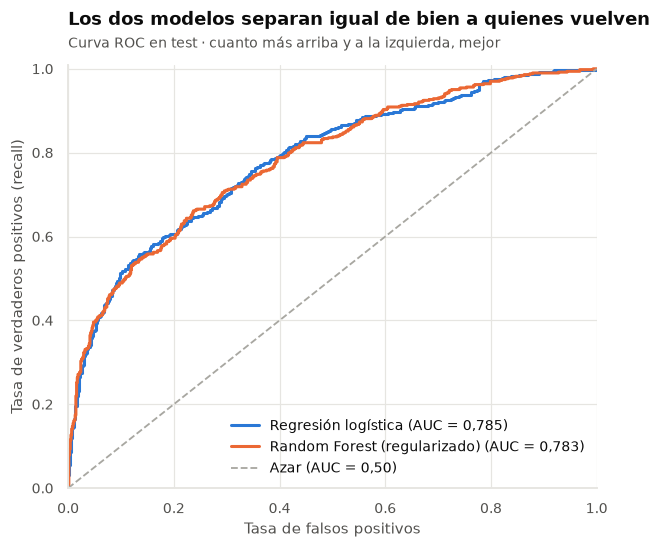

In [27]:
fig, ax = plt.subplots(figsize=(6.2, 5))
colores_modelo = {'Regresión logística': AZUL, 'Random Forest (regularizado)': NARANJA}

for nombre in finalistas:
    probabilidad = pipelines[nombre].predict_proba(X_test)[:, 1]
    falsos_positivos, verdaderos_positivos, _ = roc_curve(y_test, probabilidad)
    auc = roc_auc_score(y_test, probabilidad)
    ax.plot(falsos_positivos, verdaderos_positivos, color=colores_modelo[nombre], linewidth=2,
            label=f'{nombre} (AUC = {auc:.3f})'.replace('.', ','))
ax.plot([0, 1], [0, 1], linestyle='--', color=GRIS, linewidth=1.2, label='Azar (AUC = 0,50)')

ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos (recall)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc='lower right')
titular(ax, 'Los dos modelos separan igual de bien a quienes vuelven',
        'Curva ROC en test · cuanto más arriba y a la izquierda, mejor')
plt.show()

**Qué se ve.** Las dos curvas quedan muy por encima de la diagonal del azar y prácticamente superpuestas: AUC de 0,785 para la regresión logística y 0,783 para el Random Forest. Un AUC de 0,785 significa que, si se toma al azar una compra con recompra y una sin recompra, el modelo le asigna mayor probabilidad a la primera en el 78,5% de los casos.

**Qué implica.** El resultado es bueno sin ser sospechoso. El curso advierte que un resultado casi perfecto suele esconder una variable que filtra la respuesta; un AUC cercano a 0,78 es coherente con un comportamiento humano que tiene una parte de azar que ninguna variable explica.

## 4.4 Lectura de los resultados

**El test confirma lo que mostró la validación:** los dos modelos rinden prácticamente igual, y la regresión logística elegida no pierde frente al Random Forest. La brecha de accuracy entre train y test es chica en los dos, sin señales de sobreajuste.

**Contra las referencias:**

- Frente a la clase mayoritaria, el accuracy sube de 59,8% a 74,3%.
- Frente a la regla "ya compró antes", el accuracy sube de 66,6% a 74,3%, la precision de 57,1% a 75,4% y el AUC de 0,670 a 0,785. El objetivo planteado en 4.1 se cumple.
- **Donde el modelo no gana:** con el umbral estándar de 0,5, el F1 empata con el de la regla (0,626 contra 0,624) y el recall es menor (53,5% contra 68,7%). La regla detecta más recompras, a costa de equivocarse mucho más cuando dice "vuelve". La ventaja real del modelo es otra: la regla solo sabe decir sí o no, mientras que el modelo entrega una **probabilidad** para cada compra, que permite ordenarlas y mover el umbral según el presupuesto (punto 4.6).

## 4.5 ¿Qué aprendió el modelo?

### Gráfico 9 · Coeficientes de la regresión logística

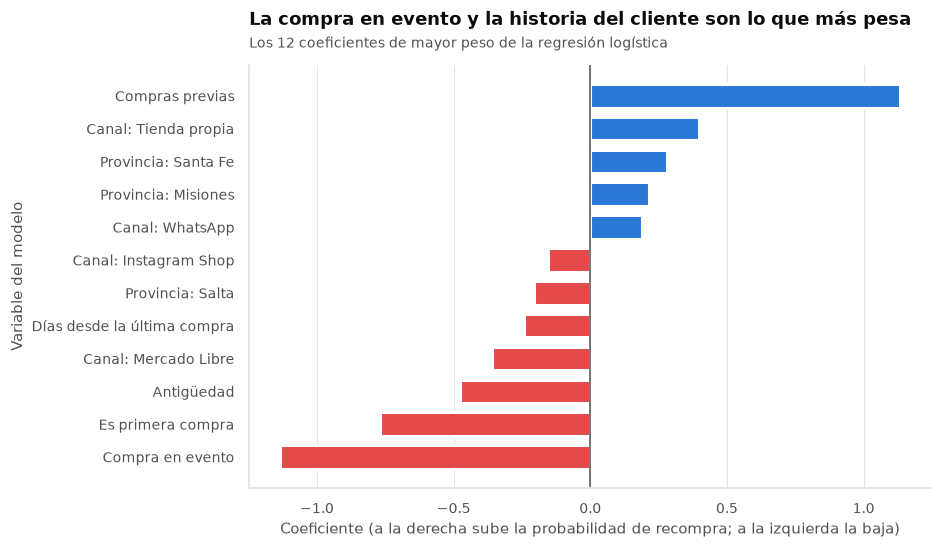

,es_evento,es_primera_compra,antiguedad_dias,canal_Mercado Libre,dias_desde_ultima_compra,provincia_Salta,canal_Instagram Shop,categoria_Indumentaria,provincia_Tucumán,provincia_Entre Ríos,provincia_Córdoba,cantidad,medio_pago_Tarjeta de crédito,provincia_Neuquén,medio_pago_Billetera virtual,medio_pago_No informado,descuento_pct,monto_real,categoria_Hogar,categoria_Tecnología,provincia_Buenos Aires,categoria_Belleza,provincia_CABA,cuotas,medio_pago_Tarjeta de débito,medio_pago_Transferencia,provincia_Mendoza,categoria_Deportes,canal_WhatsApp,provincia_Misiones,provincia_Santa Fe,canal_Tienda propia,compras_previas
coeficiente,-1.135,-0.768,-0.477,-0.359,-0.242,-0.205,-0.155,-0.141,-0.136,-0.122,-0.099,-0.058,-0.055,-0.038,-0.031,0.003,0.006,0.013,0.016,0.036,0.042,0.043,0.048,0.054,0.073,0.082,0.087,0.117,0.189,0.214,0.282,0.397,1.134


In [28]:
modelo_final = pipelines['Regresión logística']
nombres_columnas = (numericas + binarias +
                    list(modelo_final.named_steps['preprocesamiento']
                         .named_transformers_['categoricas'].get_feature_names_out(categoricas)))
coeficientes = (pd.Series(modelo_final.named_steps['modelo'].coef_[0], index=nombres_columnas)
                  .sort_values())

# Muestro los 12 coeficientes de mayor peso (en valor absoluto), ordenados de negativo a positivo
extremos = coeficientes[coeficientes.abs().sort_values(ascending=False).head(12).index].sort_values()
etiquetas_legibles = (extremos.index.str.replace('canal_', 'Canal: ').str.replace('categoria_', 'Categoría: ')
                      .str.replace('medio_pago_', 'Medio de pago: ').str.replace('provincia_', 'Provincia: ')
                      .str.replace('es_primera_compra', 'Es primera compra').str.replace('es_evento', 'Compra en evento')
                      .str.replace('compras_previas', 'Compras previas').str.replace('antiguedad_dias', 'Antigüedad')
                      .str.replace('dias_desde_ultima_compra', 'Días desde la última compra')
                      .str.replace('descuento_pct', 'Descuento').str.replace('monto_real', 'Monto real')
                      .str.replace('cantidad', 'Cantidad').str.replace('cuotas', 'Cuotas'))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(etiquetas_legibles, extremos.values, color=[ROJO if valor < 0 else AZUL for valor in extremos.values],
        edgecolor='white', linewidth=2, height=0.72)
ax.axvline(0, color=TEXTO_2, linewidth=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Coeficiente (a la derecha sube la probabilidad de recompra; a la izquierda la baja)')
ax.set_ylabel('Variable del modelo')
titular(ax, 'La compra en evento y la historia del cliente son lo que más pesa',
        'Los 12 coeficientes de mayor peso de la regresión logística')
plt.show()

display(coeficientes.round(3).to_frame('coeficiente').T)

**Cómo leerlo.** Un coeficiente positivo sube la probabilidad de recompra y uno negativo la baja. Las escalas no son idénticas: en las numéricas el coeficiente corresponde a un aumento de un desvío estándar (por el `StandardScaler`), y en las binarias y las categorías, a pasar de 0 a 1. Por eso el gráfico sirve para ver el signo y el orden de magnitud, no para un ranking exacto.

**Qué aprendió.** El modelo reconstruye lo que mostró el EDA, lo que da confianza en que aprendió patrones reales:

- **Suben la recompra:** las compras previas (el coeficiente positivo más alto) y comprar por la tienda propia.
- **Bajan la recompra:** la compra en evento, ser primera compra, comprar por Mercado Libre y los días desde la última compra.
- **Antigüedad con signo negativo:** parece contradecir al EDA, pero no lo hace. El coeficiente se lee *a igualdad del resto*: entre dos clientes con la misma cantidad de compras previas, el más antiguo las hizo más espaciadas, es decir, compra con menos frecuencia.
- **Provincias:** algunas aparecen con coeficientes medianos. No hay una hipótesis de negocio que los explique y pueden ser ruido de la muestra, así que no saco conclusiones de ellas.

Son asociaciones, no causas: que Mercado Libre tenga coeficiente negativo no prueba que mover a un cliente a la tienda propia lo vuelva más fiel.

## 4.6 Del modelo a la decisión: ordenar clientes por probabilidad

### Gráfico 10 · Recompra real según la probabilidad predicha

,compras,probabilidad_media,recompra_real
grupo,,,
20% más bajo,252,0.132,0.147
20-40%,251,0.232,0.199
40-60%,251,0.338,0.371
60-80%,251,0.487,0.474
20% más alto,251,0.819,0.821


Cortes de probabilidad entre grupos: [0.19, 0.28, 0.39, 0.63]


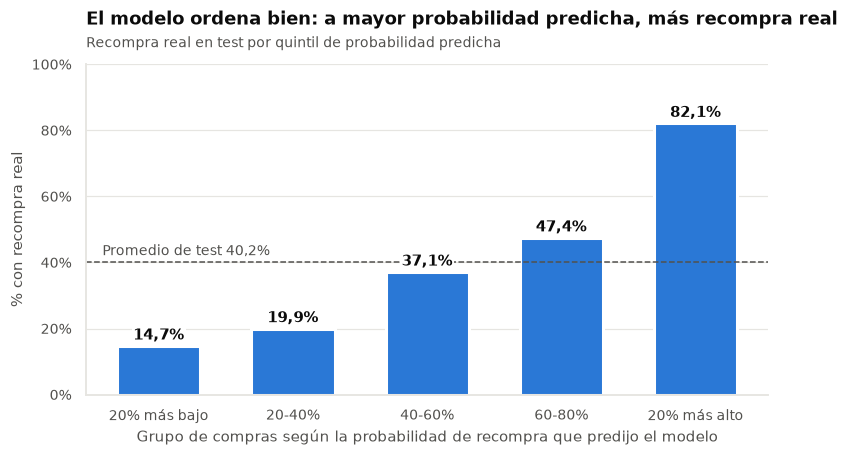

In [29]:
# Divido las compras de test en 5 grupos de igual tamaño según la probabilidad que predijo el modelo.
# retbins devuelve además los cortes de probabilidad que separan a los grupos
probabilidad_test = modelo_final.predict_proba(X_test)[:, 1]
ranking = pd.DataFrame({'probabilidad': probabilidad_test, 'volvio': y_test.values})
nombres_grupos = ['20% más bajo', '20-40%', '40-60%', '60-80%', '20% más alto']
ranking['grupo'], cortes = pd.qcut(ranking['probabilidad'], q=5, labels=nombres_grupos, retbins=True)

por_grupo = ranking.groupby('grupo', observed=True).agg(
    compras=('volvio', 'size'),
    probabilidad_media=('probabilidad', 'mean'),
    recompra_real=('volvio', 'mean'),
)
display(por_grupo.round(3))
print('Cortes de probabilidad entre grupos:', [round(float(corte), 2) for corte in cortes[1:-1]])

fig, ax = plt.subplots(figsize=(8, 3.9))
ax.bar(por_grupo.index.astype(str), por_grupo['recompra_real'] * 100, color=AZUL, width=0.62,
       edgecolor='white', linewidth=2)
for posicion, valor in enumerate(por_grupo['recompra_real']):
    ax.text(posicion, valor * 100 + 2, pct(valor), ha='center', fontsize=10, fontweight='bold', color=TEXTO,
            zorder=5, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.axhline(y_test.mean() * 100, color=TEXTO_2, linewidth=1, linestyle='--')
ax.text(-0.42, y_test.mean() * 100 + 2, f'Promedio de test {pct(y_test.mean())}', fontsize=9, color=TEXTO_2)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis='x', visible=False)
ax.set_xlabel('Grupo de compras según la probabilidad de recompra que predijo el modelo')
ax.set_ylabel('% con recompra real')
titular(ax, 'El modelo ordena bien: a mayor probabilidad predicha, más recompra real',
        'Recompra real en test por quintil de probabilidad predicha')
plt.show()

**Qué se ve.** La recompra real crece en cada escalón: en el 20% de compras con menor probabilidad predicha volvió el 14,7%, y en el 20% con mayor probabilidad, el 82,1%. La probabilidad media predicha en cada grupo queda cerca de la recompra real, así que la probabilidad se puede leer casi de forma literal.

**Qué implica.** El valor del modelo para el negocio no está en el sí o no, sino en el orden: permite separar tres zonas con decisiones distintas (sección 5).

**¿Quiénes están en cada zona?** Antes de recomendar una acción distinta para cada una, miro qué compras caen en el 20% más bajo, el 60% central y el 20% más alto.

In [30]:
perfil = X_test.copy()
perfil['volvio'] = y_test.values
perfil['zona'] = ranking['grupo'].astype(str).map(
    {'20% más bajo': '1. Probabilidad baja (20% inferior)',
     '20% más alto': '3. Probabilidad alta (20% superior)'}).fillna('2. Probabilidad media (60% central)').values

perfil_zonas = perfil.groupby('zona').agg(
    compras=('volvio', 'size'),
    recompra_real=('volvio', 'mean'),
    primeras_compras=('es_primera_compra', 'mean'),
    compras_en_evento=('es_evento', 'mean'),
    por_tienda_propia=('canal', lambda canal: (canal == 'Tienda propia').mean()),
    por_mercado_libre=('canal', lambda canal: (canal == 'Mercado Libre').mean()),
    recencia_mediana_dias=('dias_desde_ultima_compra', 'median'),      # solo recurrentes: los nuevos no tienen
)
display(perfil_zonas.round(3))

,compras,recompra_real,primeras_compras,compras_en_evento,por_tienda_propia,por_mercado_libre,recencia_mediana_dias
zona,,,,,,,
1. Probabilidad baja (20% inferior),252,0.147,0.877,0.679,0.139,0.627,165.0
2. Probabilidad media (60% central),753,0.348,0.567,0.064,0.317,0.344,70.5
3. Probabilidad alta (20% superior),251,0.821,0.000,0.052,0.661,0.072,31.0


**Qué se ve.** Las tres zonas tienen perfiles distintos:

- **Probabilidad baja** (menos de 0,19): el 88% son primeras compras, y cerca de dos de cada tres se hicieron en un evento (68%) o por Mercado Libre (63%). Los pocos recurrentes que caen acá llevaban más de cinco meses sin comprar.
- **Probabilidad alta** (más de 0,63): no hay ninguna primera compra. Son clientes recurrentes que compraron hace poco (recencia mediana de 31 días) y, en su mayoría, por la tienda propia (66%).
- **Probabilidad media:** es la zona mixta. El 57% son primeras compras, casi todas hechas fuera de evento, y el resto son recurrentes con una recencia mediana de 70 días.

El umbral de 0,5 es una convención, no una obligación. La tabla siguiente muestra cómo cambian precision y recall al moverlo. Es ilustrativa: el umbral definitivo debería elegirse con el costo real de cada acción de retención, no mirando el test.

In [31]:
filas_umbral = []
for umbral in [0.30, 0.40, 0.50, 0.60, 0.70]:
    prediccion = (probabilidad_test >= umbral).astype(int)
    filas_umbral.append({
        'umbral': umbral,
        'compras marcadas como "vuelve"': int(prediccion.sum()),
        'precision': precision_score(y_test, prediccion),
        'recall': recall_score(y_test, prediccion),
        'f1': f1_score(y_test, prediccion),
    })
display(pd.DataFrame(filas_umbral).set_index('umbral').round(3))

,"compras marcadas como ""vuelve""",precision,recall,f1
umbral,,,,
0.3,716,0.567,0.804,0.665
0.4,474,0.662,0.622,0.641
0.5,358,0.754,0.535,0.626
0.6,269,0.810,0.432,0.563
0.7,195,0.862,0.333,0.480


## 4.7 Validación temporal: ¿el modelo sirve para predecir el futuro?

La separación aleatoria mezcla compras de todo el período. En producción, en cambio, el modelo se entrena con el pasado y se usa sobre compras futuras. Para comprobar que el resultado no depende de esa mezcla, simulo estar parado el **31/12/2025**:

- **Train:** compras hasta el 02/10/2025. Son las únicas cuyo resultado a 90 días ya se conocía el 31/12/2025.
- **Test:** compras del 01/01/2026 al 01/04/2026, que el modelo nunca vio.

Es una prueba más exigente y con menos datos de entrenamiento. No reemplaza a la evaluación principal: la complementa.

In [32]:
fechas = df['fecha']
train_pasado = fechas <= '2025-10-02'
test_futuro = fechas >= '2026-01-01'

modelo_temporal = Pipeline([('preprocesamiento', crear_preprocesador()),
                            ('modelo', LogisticRegression(max_iter=1000, random_state=SEMILLA))])
modelo_temporal.fit(X[train_pasado], y[train_pasado])

prediccion_futuro = modelo_temporal.predict(X[test_futuro])
probabilidad_futuro = modelo_temporal.predict_proba(X[test_futuro])[:, 1]

metricas_futuro = medir(y[test_futuro], prediccion_futuro, probabilidad_futuro)
referencias_futuro = medir_referencias(X[test_futuro], y[test_futuro])

validacion = pd.DataFrame({
    'Separación aleatoria · regresión logística': tabla_test.loc['Regresión logística'],
    'Validación temporal · regresión logística': metricas_futuro,
    'Validación temporal · clase mayoritaria': referencias_futuro['Ref. 1 · Clase mayoritaria'],
    'Validación temporal · regla "ya compró antes"': referencias_futuro['Ref. 2 · Regla "ya compró antes"'],
}).T
print(f'Train: {miles(train_pasado.sum())} compras hasta el 02/10/2025 | Test: {miles(test_futuro.sum())} compras de 2026 '
      f'(recompra: {pct(y[test_futuro].mean())})')
print(f'Compras en evento: {miles(X.loc[train_pasado, "es_evento"].sum())} en train | '
      f'{miles(X.loc[test_futuro, "es_evento"].sum())} en test')
display(validacion.round(3))

Train: 3.659 compras hasta el 02/10/2025 | Test: 1.200 compras de 2026 (recompra: 46,2%)
Compras en evento: 583 en train | 0 en test


,accuracy,precision,recall,f1,roc_auc
Separación aleatoria · regresión logística,0.743,0.754,0.535,0.626,0.785
Validación temporal · regresión logística,0.719,0.752,0.586,0.659,0.765
Validación temporal · clase mayoritaria,0.538,0.000,0.000,0.000,0.500
"Validación temporal · regla ""ya compró antes""",0.645,0.591,0.755,0.663,0.653


**Resultado.** Entrenado solo con el pasado y evaluado sobre compras de 2026, el modelo tiene un rendimiento parecido al de la separación aleatoria: accuracy de 71,9% y AUC de 0,765, contra 74,3% y 0,785. Una caída chica es esperable, porque entrena con menos datos y predice un período que no conoce.

**Cómo leerlo con cuidado**

- Las métricas de los dos períodos no son directamente comparables. En el primer trimestre de 2026 la recompra es más alta (46,2% contra 40,2%), porque el negocio ya tiene más clientes recurrentes. Por eso la comparación justa es contra las referencias medidas en ese mismo período: el modelo supera a la clase mayoritaria (53,8% de accuracy) y a la regla (64,5% de accuracy y 0,653 de AUC).
- Igual que en test, el F1 de la regla queda a la par del modelo (0,663 contra 0,659): la ventaja del modelo sigue estando en la precision y en el orden, no en el F1.
- En el período de prueba no hubo ningún evento de descuento. Esta validación no dice nada sobre cómo predice el modelo las compras de un Hot Sale o CyberMonday futuro.

Con esas salvedades, es evidencia a favor de que el modelo sirve para el uso real (entrenar con el pasado, predecir compras nuevas), no una prueba definitiva.

## 4.8 ¿Cuánto depende el resultado de la partición?

Todas las métricas anteriores salen de una única separación en train y test. Para saber cuánto pesa el azar de esa separación, repito el proceso completo (separar, entrenar la regresión logística, medir) con 20 semillas distintas y miro cuánto se mueven los resultados.

In [33]:
filas_semillas = []
for semilla in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=semilla)
    modelo_semilla = crear_pipeline(LogisticRegression(max_iter=1000, random_state=SEMILLA)).fit(X_tr, y_tr)
    del_modelo = evaluar(modelo_semilla, X_te, y_te)
    de_la_regla = medir_referencias(X_te, y_te)['Ref. 2 · Regla "ya compró antes"']
    filas_semillas.append({'accuracy modelo': del_modelo['accuracy'], 'accuracy regla': de_la_regla['accuracy'],
                           'roc_auc modelo': del_modelo['roc_auc'], 'roc_auc regla': de_la_regla['roc_auc'],
                           'f1 modelo': del_modelo['f1'], 'f1 regla': de_la_regla['f1']})

semillas = pd.DataFrame(filas_semillas)
display(semillas.agg(['mean', 'min', 'max']).T.round(3))
print('Particiones en las que el modelo supera a la regla:',
      {metrica: f"{int((semillas[metrica + ' modelo'] > semillas[metrica + ' regla']).sum())} de 20"
       for metrica in ['accuracy', 'roc_auc', 'f1']})

,mean,min,max
accuracy modelo,0.731,0.715,0.744
accuracy regla,0.651,0.627,0.670
roc_auc modelo,0.775,0.762,0.790
roc_auc regla,0.660,0.636,0.681
f1 modelo,0.613,0.594,0.635
f1 regla,0.619,0.595,0.642


Particiones en las que el modelo supera a la regla: {'accuracy': '20 de 20', 'roc_auc': '20 de 20', 'f1': '7 de 20'}


**Qué se ve.**

- **El resultado es estable.** En las 20 particiones el accuracy del modelo queda entre 71,5% y 74,4% (promedio de 73,1%) y el ROC-AUC entre 0,762 y 0,790 (promedio de 0,775).
- **El objetivo se cumple siempre.** El modelo supera a la regla "ya compró antes" en accuracy y en ROC-AUC en las 20 particiones, no solo en la principal.
- **La partición principal salió algo favorecida.** Su 74,3% de accuracy está cerca del máximo del rango. La cifra más representativa de lo que se puede esperar es el promedio: alrededor de 73% de accuracy y 0,775 de AUC.
- **En F1 no hay ventaja.** El modelo supera a la regla solo en 7 de las 20 particiones, y en promedio queda apenas por debajo (0,613 contra 0,619). Confirma lo que mostró el punto 4.4: con el umbral de 0,5 el modelo es más preciso pero detecta menos recompras que la regla, y su aporte está en la probabilidad, que permite ordenar y elegir el umbral.

Esta prueba se hizo después de elegir el modelo y no cambia ninguna decisión: solo mide cuánta confianza merecen las cifras.

---
# 5. Conclusiones y recomendaciones

## 5.1 ¿Qué aprendimos de los datos?

1. **La historia del cliente es lo que más anticipa la recompra.** Un cliente en su primera compra vuelve en el 24,0% de los casos; con cinco o más compras previas, en el 79,4%. Entre los recurrentes, los que vuelven venían de comprar hace 40 días (mediana) y los que no, hace 71.
2. **La segunda compra es el cuello de botella.** Casi la mitad de las compras son de clientes nuevos, y solo uno de cada cuatro vuelve.
3. **El canal importa, y no solo por la mezcla de clientes.** La tienda propia es el canal que más retiene y Mercado Libre el que menos: 33,3% contra 16,9% en clientes nuevos (casi el doble) y 67,5% contra 41,6% en recurrentes. Además, la tienda propia cobra 6% de comisión, contra 14% a 17% de Mercado Libre.
4. **Los eventos captan compradores, no clientes.** Solo el 7,6% de los clientes nuevos captados en Hot Sale o CyberMonday vuelve, contra 29,0% de los captados fuera de evento.
5. **El monto de la compra no anticipa la recompra** (correlación de 0,02 con el target).
6. **La recompra se puede predecir de forma útil, no perfecta.** La regresión logística alcanza 74,3% de accuracy y 0,785 de AUC en test (alrededor de 73% y 0,775 en promedio al repetir la partición), contra 59,8% de la clase mayoritaria y 66,6% de la regla "ya compró antes", y mantiene un rendimiento parecido al predecir compras de un período posterior al de entrenamiento (punto 4.7).

## 5.2 ¿Qué debería hacer el negocio?

**Recomendación: usar la probabilidad del modelo para repartir el presupuesto de retención en tres zonas**, en lugar de darle el mismo incentivo a todos. Según el ranking del gráfico 10 y el perfil de cada zona (punto 4.6):

| Zona | Quiénes son | Qué pasa en la realidad (test) | Acción recomendada |
|---|---|---|---|
| **Probabilidad alta** (20% superior) | Clientes recurrentes que compraron hace poco, la mayoría por la tienda propia | Vuelve el 82,1% | **No regalar margen.** Sin descuentos; solo comunicación de marca o novedades. |
| **Probabilidad media** (60% central) | Zona mixta: primeras compras hechas fuera de evento y recurrentes con menos actividad | Vuelve entre el 19,9% y el 47,4% | **Concentrar acá el presupuesto.** Es donde un incentivo puede cambiar el resultado: recordatorio a los 30-45 días, envío gratis o cupón para la próxima compra. |
| **Probabilidad baja** (20% inferior) | Casi todas primeras compras, en su mayoría hechas en evento y por Mercado Libre | Vuelve el 14,7% | **Solo acciones de costo casi nulo** (email automático). Un descuento acá tiene retorno esperado bajo. |

Dos decisiones complementarias que salen del EDA:

- **Atacar la segunda compra:** un incentivo específico para clientes nuevos captados *fuera* de evento, que son los que tienen margen real de mejora (29,0% de recompra).
- **Llevar clientes de Mercado Libre a la tienda propia** (por ejemplo, con un cupón dentro del paquete): cobra 6% de comisión contra 14% a 17% de Mercado Libre, y es el canal donde los clientes más vuelven. Conviene medirlo con una prueba controlada, porque la diferencia observada no prueba causalidad.

**Cómo medir si funciona:** antes de aplicarlo a toda la base, hacer una prueba con grupo de control (una parte de cada zona no recibe el incentivo) y comparar la recompra a 90 días. Es la única forma de saber cuántas recompras *generó* la acción y cuántas iban a ocurrir igual.

## 5.3 Limitaciones y próximos pasos

**Limitaciones**

- **El dataset es sintético.** Las relaciones encontradas son las reglas con las que se generaron los datos más ruido. El valor del proyecto está en el método (limpieza, partición sin fugas, evaluación honesta); antes de usarlo en un negocio real hay que reentrenarlo con sus datos.
- **El modelo predice quién vuelve, no a quién conviene incentivar.** Que un cliente tenga probabilidad media no garantiza que un descuento lo haga volver. Para eso hace falta la prueba controlada del punto 5.2.
- **Faltan variables que en un e-commerce real existen:** navegación en el sitio, apertura de emails, reclamos, devoluciones, tiempos de entrega, datos demográficos.
- **Quince meses de historia** incluyen un solo Hot Sale y un solo CyberMonday: lo que el modelo aprendió sobre los eventos sale de dos episodios, y no alcanza para separar estacionalidad de tendencia.
- **Las métricas tienen margen de error.** Con otra partición el accuracy se mueve unos puntos (punto 4.8), así que las cifras de test son una estimación, no un valor exacto. Y con el umbral de 0,5 el modelo no supera a la regla simple en F1: su aporte está en la precision y en el orden por probabilidad.
- **Varias compras de un mismo cliente pueden quedar repartidas entre train y test.** No uso el identificador del cliente como variable, y la validación temporal confirma el resultado, pero una partición por cliente sería más estricta.
- **El umbral de decisión quedó en 0,5.** El óptimo depende del costo de cada incentivo y del margen de una recompra, datos que este dataset no tiene.

**Qué mejoraría en una segunda versión**

1. Validación cruzada y ajuste de hiperparámetros.
2. Probar modelos de boosting y nuevas variables (ciclo promedio de compra del cliente, categoría de la compra anterior).
3. Definir el umbral con una matriz de costos del negocio.
4. Agregar una segmentación de clientes por clustering (K-Means sobre recencia, frecuencia y monto) para diseñar un mensaje distinto por segmento.
5. Pasar de "¿quién vuelve?" a "¿a quién le cambia la decisión un incentivo?", con datos de campañas reales.

---
*Luciano Rivero · Proyecto Final de Data Science I · Coderhouse · Noviembre 2026*